# Genetic Drift at a Biallelic Locus

## Objective

This notebook explores genetic drift in a finite population using the haploid Wright-Fisher model, focusing on a single locus with two possible alleles, denoted 0 and 1.

The objective is to investigate how random genetic drift affects allele frequencies over generations, and how population size and initial allele frequency influence the probability and timing of fixation.

Through a series of stochastic simulations, we aim to illustrate three main properties:

- The random evolution of allele frequencies over generations.
- The probability that an allele eventually becomes fixed in the population.
- The time required for genetic drift to eliminate one of the two alleles (absorption).

## Model assumptions

We consider a population satisfying the following assumptions:

* The population consists of $N$ haploid individuals.
* The generations are discrete and there is no overlap between generations.
* Each individual carries exactly one allele at the observed locus.
* There are 2 possible alleles, denoted $0$ and $1$.
* Each individual in generation $t+1$ independently inherits its allele from a randomly sampled individual in generation $t$.
* The population size remains constant across generations.
* There is no mutation, selection or migration.

Reproduction is therefore as random sampling with replacement from the previous generation.

## Population representation

We consider a single locus with two possible alleles, 0 and 1.

Each individual is therefore represented by a binary state, and the population at a given generation is represented by an array of $N$ binary values.

In this notebook, *allele frequency* refers specifically to the frequency of allele 1:

$
x(t)=\frac{\text{Number of individuals carrying allele 1 at generation }t}{N}
$

Since there are only two possible alleles, the frequency of allele 0 is simply $1-x(t)$.

## Implementation

In [47]:
import matplotlib.pyplot as plt
import numpy as np

In [46]:
def initialize_population(size: int, allele_frequency: float) -> int:
    """
    Initialize a population with a given number of copies of allele 1.
    """
    return int(np.floor(allele_frequency * size))


def calculate_allele_frequency(allele_count: int, size: int) -> float:
    """
    Calculate the frequency of allele 1 in the population.
    """
    return allele_count / size


def next_generation(allele_count: int, size: int, rng) -> int:
    """
    Simulate the next generation under neutral Wright-Fisher drift.
    """
    allele_frequency = calculate_allele_frequency(allele_count, size)
    return rng.binomial(n=size, p=allele_frequency)

In [3]:
seed = 42
rng = np.random.default_rng(seed)

## Evolution of allelic frequency

In [7]:
# Parameters
POPULATION_SIZE = 100
INITIAL_ALLELE_FREQUENCY = 0.5
MAX_GENERATIONS = 4 * POPULATION_SIZE

In [8]:
def simulate_one_population(population_size, initial_allele_frequency, rng, stop):

    current_allele_count = initialize_population(
        population_size, initial_allele_frequency
    )

    allele_frequencies = [
        calculate_allele_frequency(current_allele_count, population_size)
    ]

    fixation = False
    absorption_time = None

    if current_allele_count == population_size:
        fixation = True
        absorption_time = 0

    elif current_allele_count == 0:
        absorption_time = 0

    for generation in range(1, stop + 1):

        if absorption_time is not None:
            break

        current_allele_count = next_generation(
            current_allele_count, population_size, rng
        )

        allele_frequency = calculate_allele_frequency(
            current_allele_count, population_size
        )

        allele_frequencies.append(allele_frequency)

        if current_allele_count == population_size:
            fixation = True
            absorption_time = generation

        elif current_allele_count == 0:
            absorption_time = generation

    generations = list(range(len(allele_frequencies)))

    return generations, allele_frequencies, fixation, absorption_time

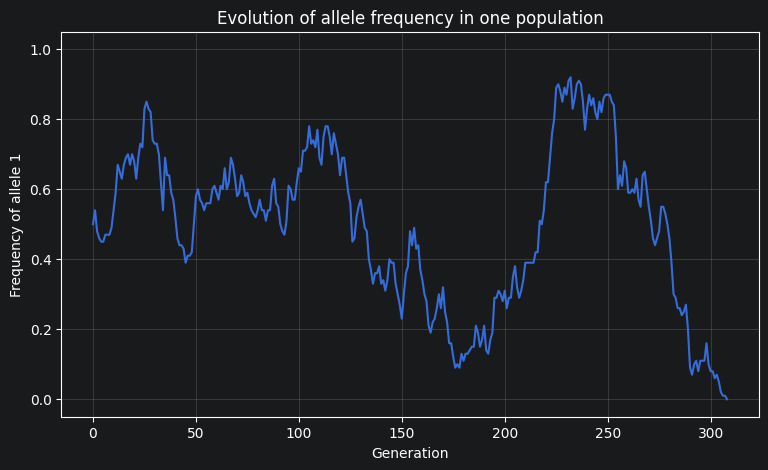

Allele 1 was lost after 308 generations.


In [9]:
generations, allele_frequencies, fixation, absorption_time = (
    simulate_one_population(
        POPULATION_SIZE,
        INITIAL_ALLELE_FREQUENCY,
        rng,
        MAX_GENERATIONS
    )
)

plt.figure(figsize=(9, 5))

plt.plot(generations, allele_frequencies, linewidth=1.5)

plt.xlabel("Generation")
plt.ylabel("Frequency of allele 1")
plt.title("Evolution of allele frequency in one population")
plt.ylim(-0.05, 1.05)
plt.grid(alpha=0.3)

plt.show()

if absorption_time is None:
    print(f"No absorption reached within {MAX_GENERATIONS} generations.")
elif fixation:
    print(f"Allele 1 reached fixation after {absorption_time} generations.")
else:
    print(f"Allele 1 was lost after {absorption_time} generations.")

## Multiple simulations for evolution of allelic frequency

In [14]:
# Parameters
SIMULATION_NUMBER = 1000
POPULATION_SIZE = 100
INITIAL_ALLELE_FREQUENCY = 0.5
MAX_GENERATIONS = 4 * POPULATION_SIZE

In [16]:
def simulate_n_populations(
    simulation_number, population_size, initial_allele_frequency, rng, stop
):

    allele_frequencies = np.zeros((simulation_number, stop + 1))

    fixation_count = 0
    loss_count = 0
    absorption_times = []

    for s in range(simulation_number):

        current_allele_count = initialize_population(
            population_size, initial_allele_frequency
        )

        allele_frequencies[s, 0] = calculate_allele_frequency(
            current_allele_count, population_size
        )

        absorption_time = None

        if current_allele_count == population_size:
            fixation_count += 1
            absorption_time = 0

        elif current_allele_count == 0:
            loss_count += 1
            absorption_time = 0

        for generation in range(1, stop + 1):

            if absorption_time is not None:
                allele_frequencies[s, generation] = (
                    allele_frequencies[s, generation - 1]
                )
                continue

            current_allele_count = next_generation(
                current_allele_count, population_size, rng
            )

            allele_frequency = calculate_allele_frequency(
                current_allele_count, population_size
            )

            allele_frequencies[s, generation] = allele_frequency

            if current_allele_count == population_size:
                fixation_count += 1
                absorption_time = generation

            elif current_allele_count == 0:
                loss_count += 1
                absorption_time = generation

        if absorption_time is not None:
            absorption_times.append(absorption_time)

    absorption_count = fixation_count + loss_count

    return (
        allele_frequencies,
        fixation_count,
        loss_count,
        absorption_times
    )

In [17]:
allele_frequencies, fixation_count, loss_count, absorption_times = (
    simulate_n_populations(
        SIMULATION_NUMBER,
        POPULATION_SIZE,
        INITIAL_ALLELE_FREQUENCY,
        rng,
        MAX_GENERATIONS
    )
)

absorption_count = fixation_count + loss_count
incomplete_count = SIMULATION_NUMBER - absorption_count

print(f"Absorption: {absorption_count}/{SIMULATION_NUMBER} "
      f"({absorption_count / SIMULATION_NUMBER:.1%})")

print(f"  - Fixation of allele 1: {fixation_count}/{SIMULATION_NUMBER} "
      f"({fixation_count / SIMULATION_NUMBER:.1%})")

print(f"  - Loss of allele 1: {loss_count}/{SIMULATION_NUMBER} "
      f"({loss_count / SIMULATION_NUMBER:.1%})")

print(f"Not absorbed: {incomplete_count}/{SIMULATION_NUMBER} "
      f"({incomplete_count / SIMULATION_NUMBER:.1%})")

if absorption_times:
    print(f"Mean absorption time: {np.mean(absorption_times):.1f} generations")

Absorption: 973/1000 (97.3%)
  - Fixation of allele 1: 472/1000 (47.2%)
  - Loss of allele 1: 501/1000 (50.1%)
Not absorbed: 27/1000 (2.7%)
Mean absorption time: 126.0 generations


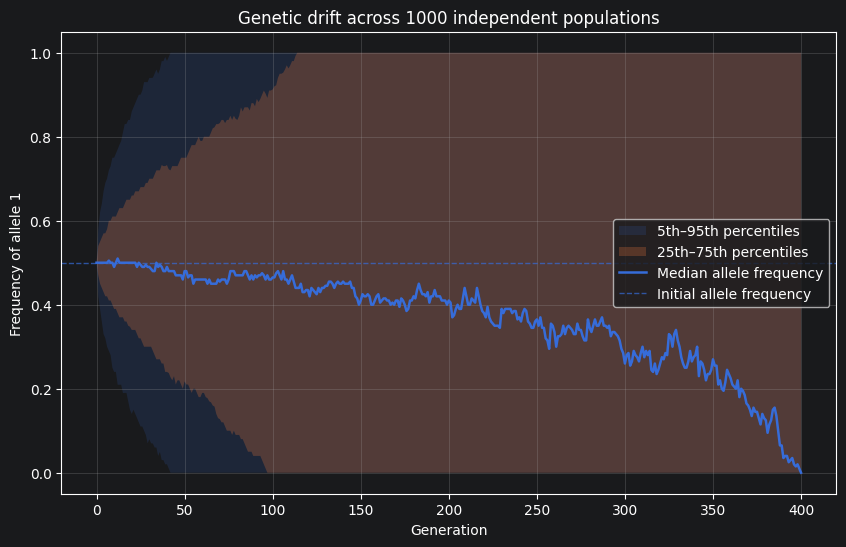

In [18]:
generations = np.arange(MAX_GENERATIONS + 1)

percentiles = np.percentile(
    allele_frequencies,
    [5, 25, 50, 75, 95],
    axis=0
)

p5, p25, median, p75, p95 = percentiles

initial_frequency = allele_frequencies[0, 0]

plt.figure(figsize=(10, 6))

plt.fill_between(
    generations, p5, p95,
    alpha=0.15,
    label="5th–95th percentiles"
)

plt.fill_between(
    generations, p25, p75,
    alpha=0.3,
    label="25th–75th percentiles"
)

plt.plot(
    generations, median,
    linewidth=1.8,
    label="Median allele frequency"
)

plt.axhline(
    initial_frequency,
    linestyle="--",
    linewidth=1,
    alpha=0.7,
    label="Initial allele frequency"
)

plt.xlabel("Generation")
plt.ylabel("Frequency of allele 1")
plt.title(f"Genetic drift across {SIMULATION_NUMBER} independent populations")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.grid(alpha=0.3)

plt.show()

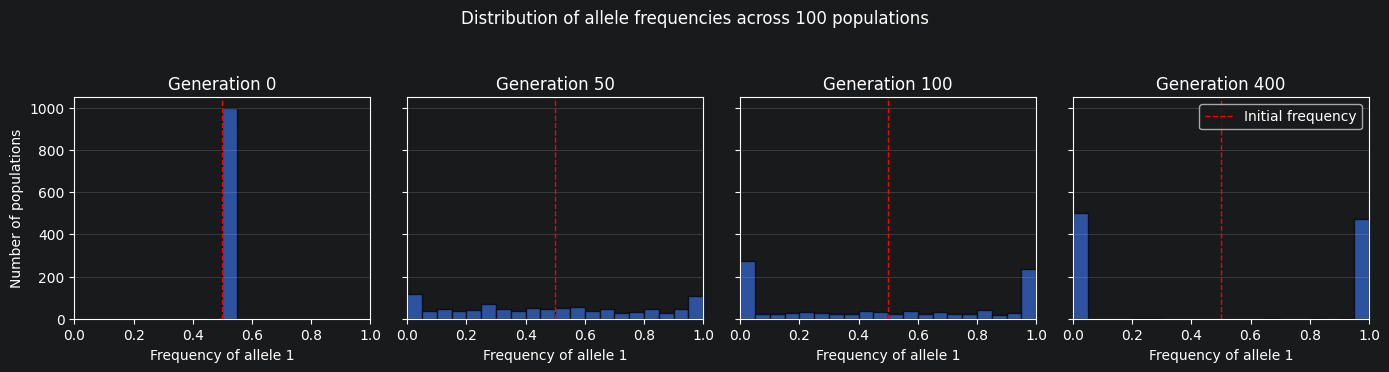

In [27]:
GENERATIONS_TO_PLOT = [
    0,
    POPULATION_SIZE // 2,
    1 * POPULATION_SIZE,
    4 * POPULATION_SIZE
]

fig, axes = plt.subplots(
    1, len(GENERATIONS_TO_PLOT),
    figsize=(14, 3.5),
    sharey=True
)

for ax, generation in zip(axes, GENERATIONS_TO_PLOT):

    ax.hist(
        allele_frequencies[:, generation],
        bins=np.linspace(0, 1, 21),
        edgecolor="black",
        alpha=0.7
    )

    ax.axvline(
        INITIAL_ALLELE_FREQUENCY,
        color="red",
        linestyle="--",
        linewidth=1,
        label="Initial frequency"
    )

    ax.set_title(f"Generation {generation}")
    ax.set_xlabel("Frequency of allele 1")
    ax.set_xlim(0, 1)
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Number of populations")
axes[-1].legend()

fig.suptitle(
    f"Distribution of allele frequencies across {SIMULATION_NUMBER} populations",
    y=1.05
)

plt.tight_layout()
plt.show()

## Fixation probability

Genetic drift can eventually lead to the fixation of one allele and the loss of the alternative allele. Fixation occurs when an allele reaches a frequency of 1 in the population, while loss occurs when its frequency reaches 0.

The fixation probability of an allele is the probability that it eventually becomes fixed, starting from a given initial frequency.

### Theoretical expectation under neutrality

In the neutral Wright-Fisher model, all alleles have the same reproductive success: there is no selection favoring one allele over another.

Under these assumptions, the probability that an allele eventually becomes fixed is equal to its initial frequency:

$
P(\text{fixation}) = x_0
$

where $x_0$ is the initial frequency of the allele.

This result follows from the fact that allele frequency is a martingale under neutral drift: its expected value remains constant from one generation to the next.

$
E[x_{t+1}\mid x_t]=x_t
$

Although individual populations experience random changes in allele frequency, the average frequency across many independent populations remains equal to the initial frequency. Eventually, each population reaches one of the two absorbing states (0 or 1). Consequently, the proportion of populations in which the allele becomes fixed converges to its initial frequency.

This means that an allele initially present at low frequency has a low probability of fixation, even though its fate is not deterministic. Conversely, an allele initially present at high frequency is more likely to become fixed.

In [28]:
# Parameters
SIMULATION_NUMBER = 500
POPULATION_SIZE = 100
INITIAL_ALLELE_FREQUENCIES = np.linspace(0, 1, 21)
MAX_GENERATIONS = 4 * POPULATION_SIZE

In [29]:
fixation_probabilities = []
non_absorbed_proportions = []
realized_initial_frequencies = []

for p0 in INITIAL_ALLELE_FREQUENCIES:

    allele_frequencies, fixation_count, loss_count, absorption_times = (
        simulate_n_populations(
            SIMULATION_NUMBER,
            POPULATION_SIZE,
            p0,
            rng,
            MAX_GENERATIONS
        )
    )

    absorption_count = fixation_count + loss_count
    non_absorbed_count = SIMULATION_NUMBER - absorption_count

    fixation_probabilities.append(fixation_count / SIMULATION_NUMBER)
    non_absorbed_proportions.append(non_absorbed_count / SIMULATION_NUMBER)

    # Account for the actual initial frequency after rounding down the allele count
    realized_p0 = initialize_population(POPULATION_SIZE, p0) / POPULATION_SIZE
    realized_initial_frequencies.append(realized_p0)

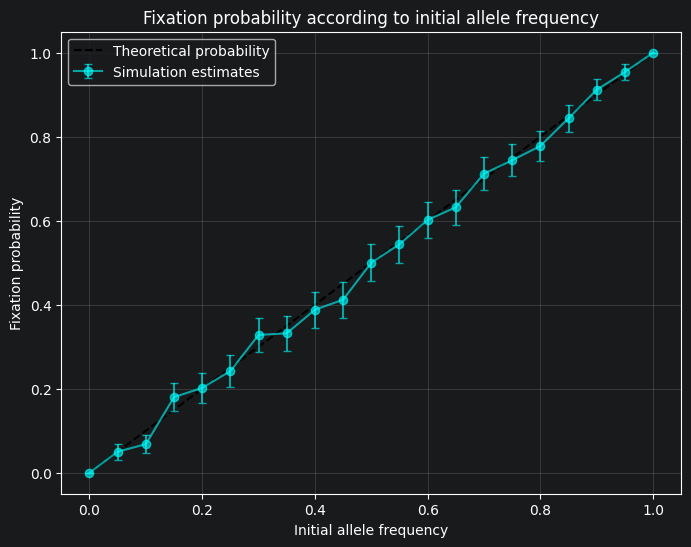

In [33]:
fixation_probabilities = np.array(fixation_probabilities)
realized_initial_frequencies = np.array(realized_initial_frequencies)

standard_errors = np.sqrt(
    fixation_probabilities * (1 - fixation_probabilities) / SIMULATION_NUMBER
)

plt.figure(figsize=(8, 6))

plt.plot(
    realized_initial_frequencies,
    realized_initial_frequencies,
    linestyle="--",
    color="black",
    label="Theoretical probability"
)

plt.errorbar(
    realized_initial_frequencies,
    fixation_probabilities,
    yerr=1.96 * standard_errors,
    fmt="o-",
    color="cyan",
    alpha=0.6,
    capsize=3,
    label="Simulation estimates"
)

plt.xlabel("Initial allele frequency")
plt.ylabel("Fixation probability")
plt.title("Fixation probability according to initial allele frequency")
plt.xlim(-0.05, 1.05)
plt.ylim(-0.05, 1.05)
plt.grid(alpha=0.3)
plt.legend()

plt.show()

## Absorption time

The absorption time is the number of generations required for an allele to reach one of the two absorbing states: fixation (frequency 1) or loss (frequency 0).

Under neutral genetic drift, the expected absorption time depends on both the initial allele frequency and the population size.

For a haploid Wright-Fisher population, the diffusion approximation gives:

$
E[T_{\mathrm{abs}}] \approx -2N\left[x_0\ln(x_0)+(1-x_0)\ln(1-x_0)\right]
$

where $N$ is the population size and $x_0$ is the initial allele frequency.

For an initial allele frequency of $x_0=0.5$:

$
E[T_{\mathrm{abs}}] \approx 2N\ln(2) \approx 1.386N
$

Thus, the expected absorption time increases approximately linearly with population size.

This illustrates an important consequence of genetic drift: larger populations take longer to reach fixation or loss, because random fluctuations in allele frequency are relatively weaker from one generation to the next.

Note that this expression is a diffusion approximation, generally used for sufficiently large populations, rather than an exact result for every finite population size.

In [35]:
# Parameters
SIMULATION_NUMBER = 1000
INITIAL_ALLELE_FREQUENCY = 0.5
POPULATION_SIZES = [20, 50, 100, 200, 500, 1000]
MAX_GENERATIONS = 4 * max(POPULATION_SIZES)

In [36]:
# Results
avg_absorption_times = []
absorption_time_errors = []
non_absorbed_proportions = []

for n in POPULATION_SIZES:

    max_generations = 10 * n

    allele_frequencies, fixation_count, loss_count, absorption_times = (
        simulate_n_populations(
            SIMULATION_NUMBER,
            n,
            INITIAL_ALLELE_FREQUENCY,
            rng,
            max_generations
        )
    )

    non_absorbed_count = SIMULATION_NUMBER - len(absorption_times)

    if absorption_times:
        avg_absorption_times.append(np.mean(absorption_times))

        # Standard error of the estimated mean
        absorption_time_errors.append(
            np.std(absorption_times, ddof=1) / np.sqrt(len(absorption_times))
            if len(absorption_times) > 1 else 0
        )
    else:
        avg_absorption_times.append(np.nan)
        absorption_time_errors.append(np.nan)

    non_absorbed_proportions.append(
        non_absorbed_count / SIMULATION_NUMBER
    )

In [37]:
for n, proportion in zip(POPULATION_SIZES, non_absorbed_proportions):
    print(f"N = {n}: {proportion:.1%} of populations not absorbed")

N = 20: 0.0% of populations not absorbed
N = 50: 0.0% of populations not absorbed
N = 100: 0.0% of populations not absorbed
N = 200: 0.0% of populations not absorbed
N = 500: 0.0% of populations not absorbed
N = 1000: 0.0% of populations not absorbed


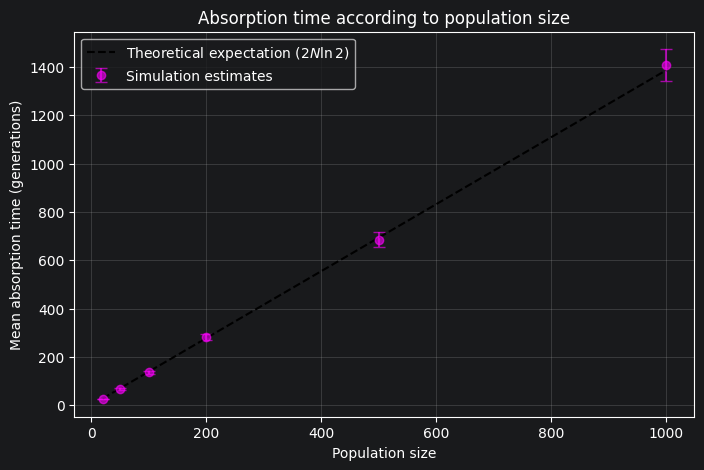

In [39]:
population_sizes = np.array(POPULATION_SIZES)
avg_absorption_times = np.array(avg_absorption_times)
absorption_time_errors = np.array(absorption_time_errors)

# Theoretical expectation under the Wright-Fisher diffusion approximation
theoretical_absorption_times = 2 * np.log(2) * population_sizes

plt.figure(figsize=(8, 5))

plt.errorbar(
    population_sizes,
    avg_absorption_times,
    yerr=1.96 * absorption_time_errors,
    fmt="o",
    capsize=4,
    alpha=0.6,
    color="magenta",
    label="Simulation estimates"
)

plt.plot(
    population_sizes,
    theoretical_absorption_times,
    linestyle="--",
    color="black",
    label=r"Theoretical expectation ($2N\ln 2$)"
)

plt.xlabel("Population size")
plt.ylabel("Mean absorption time (generations)")
plt.title("Absorption time according to population size")
plt.grid(alpha=0.3)
plt.legend()

plt.show()

In [40]:
SIMULATION_NUMBER = 1000

INITIAL_ALLELE_FREQUENCIES = [0.1, 0.25, 0.5, 0.75, 0.9]
POPULATION_SIZES = [20, 50, 100, 200, 500, 1000]

MAX_GENERATIONS_FACTOR = 10

In [41]:
results = {}

for p0 in INITIAL_ALLELE_FREQUENCIES:

    avg_absorption_times = []
    absorption_time_errors = []
    non_absorbed_proportions = []
    realized_initial_frequencies = []

    for n in POPULATION_SIZES:

        max_generations = MAX_GENERATIONS_FACTOR * n

        allele_frequencies, fixation_count, loss_count, absorption_times = (
            simulate_n_populations(
                SIMULATION_NUMBER, n, p0, rng, max_generations
            )
        )

        non_absorbed_count = SIMULATION_NUMBER - len(absorption_times)

        realized_p0 = initialize_population(n, p0) / n
        realized_initial_frequencies.append(realized_p0)

        if absorption_times:
            avg_absorption_times.append(np.mean(absorption_times))
            absorption_time_errors.append(
                np.std(absorption_times, ddof=1) / np.sqrt(len(absorption_times))
                if len(absorption_times) > 1 else 0
            )
        else:
            avg_absorption_times.append(np.nan)
            absorption_time_errors.append(np.nan)

        non_absorbed_proportions.append(
            non_absorbed_count / SIMULATION_NUMBER
        )

    results[p0] = {
        "means": np.array(avg_absorption_times),
        "errors": np.array(absorption_time_errors),
        "non_absorbed": np.array(non_absorbed_proportions),
        "realized_p0": np.array(realized_initial_frequencies)
    }

In [42]:
for p0 in INITIAL_ALLELE_FREQUENCIES:
    proportions = results[p0]["non_absorbed"]

    for n, proportion in zip(POPULATION_SIZES, proportions):
        if proportion > 0.05:
            print(
                f"Warning: p0={p0}, N={n}: "
                f"{proportion:.1%} of populations not absorbed."
            )

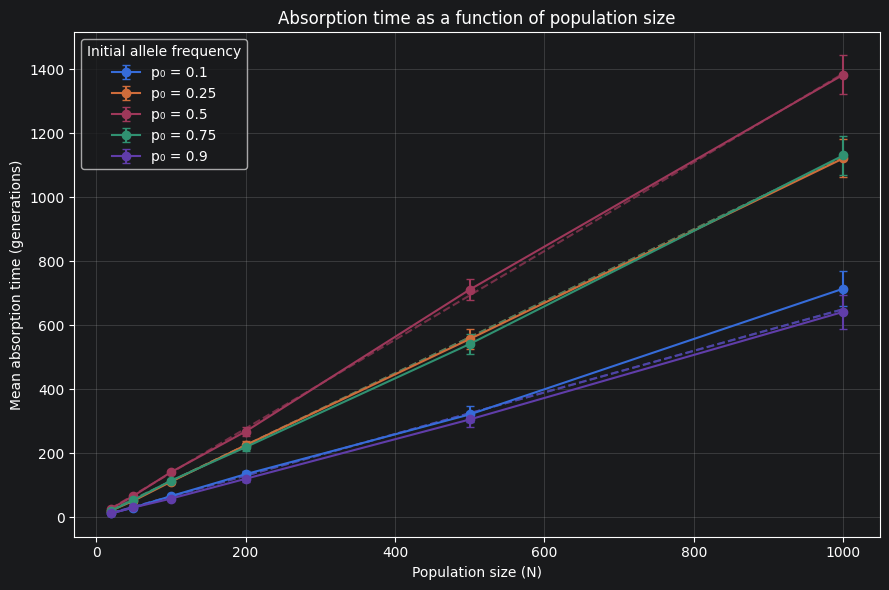

In [43]:
plt.figure(figsize=(9, 6))

for p0 in INITIAL_ALLELE_FREQUENCIES:

    means = results[p0]["means"]
    errors = results[p0]["errors"]
    realized_p0 = results[p0]["realized_p0"]

    line = plt.errorbar(
        POPULATION_SIZES,
        means,
        yerr=1.96 * errors,
        marker="o",
        capsize=3,
        label=f"p₀ = {p0}"
    )

    color = line.lines[0].get_color()

    theoretical_times = -2 * np.array(POPULATION_SIZES) * (
        realized_p0 * np.log(realized_p0)
        + (1 - realized_p0) * np.log(1 - realized_p0)
    )

    plt.plot(
        POPULATION_SIZES,
        theoretical_times,
        linestyle="--",
        color=color,
        alpha=0.7
    )

plt.xlabel("Population size (N)")
plt.ylabel("Mean absorption time (generations)")
plt.title("Absorption time as a function of population size")
plt.legend(title="Initial allele frequency")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Conclusion

This notebook explored genetic drift at a biallelic locus using the neutral Wright–Fisher model.

Through stochastic simulations, we observed that allele frequencies fluctuate randomly across generations until one allele eventually reaches fixation or is lost. The results illustrate several key properties of genetic drift:

- **Fixation probability** is equal to the initial allele frequency under neutrality.
- **Genetic diversity decreases over time**, as random sampling progressively reduces the number of alleles.
- **Absorption time increases with population size**, approximately linearly under the diffusion approximation.
- **Initial allele frequency influences absorption time**: absorption is fastest when one allele is initially rare and slowest when both alleles are equally frequent.

Overall, these simulations illustrate how random sampling alone can shape genetic variation and evolutionary outcomes, even in the absence of selection.